# 04.Pytorch custom dataset notebook

## 00.Importing the pytorch library and setup device agnostic code

In [1]:
import torch
from torch import nn

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [3]:
!nvidia-smi

Thu Nov 19 12:49:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8             12W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [4]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)
print("GPU count:", torch.cuda.device_count())
print("GPU name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

CUDA available: True
CUDA version: 13.0
GPU count: 1
GPU name: Tesla T4


## 01.get data
Our dataset is a subset of Food101 dataset

we use the minimal dataset for training

Food101 starts 101 different classes of food and 1000 images pre class,but here our dataset only start with 3 classes of food and only 10% of the images

It's always important to try things on a small scale and then increase the scale when necessary

In [5]:
import requests
import zipfile
from pathlib import Path

# Setup path to data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"

# If the image folder doesn't exist, download it and prepare it...
if image_path.is_dir():
    print(f"{image_path} directory exists.")
else:
    print(f"Did not find {image_path} directory, creating one...")
    image_path.mkdir(parents=True, exist_ok=True)

    # Download pizza, steak, sushi data
    with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        print("Downloading pizza, steak, sushi data...")
        f.write(request.content)

    # Unzip pizza, steak, sushi data
    with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
        print("Unzipping pizza, steak, sushi data...")
        zip_ref.extractall(image_path)

Did not find data/pizza_steak_sushi directory, creating one...
Unzipping pizza, steak, sushi data...


## 2.Becoming one with data(data preparation and data exploration)

In [6]:
import os

def walk_through_dir(dir_path):
    for dirpath, dirnames, filenames in os.walk(dir_path):
        print(f"There are {len(dirnames)} directories and {len(filenames)} images in '{dirpath}'.")

In [7]:
walk_through_dir(image_path)#image_path = data_path / "pizza_steak_sushi"

There are 2 directories and 0 images in 'data/pizza_steak_sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/test'.
There are 0 directories and 25 images in 'data/pizza_steak_sushi/test/pizza'.
There are 0 directories and 19 images in 'data/pizza_steak_sushi/test/steak'.
There are 0 directories and 31 images in 'data/pizza_steak_sushi/test/sushi'.
There are 3 directories and 0 images in 'data/pizza_steak_sushi/train'.
There are 0 directories and 78 images in 'data/pizza_steak_sushi/train/pizza'.
There are 0 directories and 75 images in 'data/pizza_steak_sushi/train/steak'.
There are 0 directories and 72 images in 'data/pizza_steak_sushi/train/sushi'.


In [8]:

# setup train and test path

train_dir = image_path / "train"
test_dir = image_path / "test"

print(train_dir)
print(test_dir)

data/pizza_steak_sushi/train
data/pizza_steak_sushi/test


### 2.1Visualizing and image

Let write some code to:

1. Get all of the image path
2. Pick random image path using python `random.choice()`
3. Get the image class name using pathlib.Path.parent.stem
4. Since we are working with images, lets open the image with python PIL
5. we will then show the image and print the metadata

In [9]:
image_path

PosixPath('data/pizza_steak_sushi')

Image path list : [PosixPath('data/pizza_steak_sushi/test/pizza/195160.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/194643.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/2003290.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/2218680.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/1687143.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/1925494.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/416067.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/2124579.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/2871261.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/971934.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/309892.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/1503858.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/3092704.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/2236338.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/930553.jpg'), PosixPath('data/pizza_steak_sushi/test/pizza/540882.jpg'), PosixPath('data/pizza_steak_

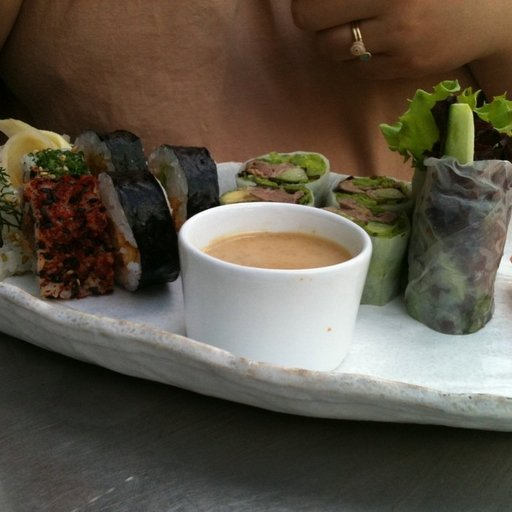

In [10]:
import random
from PIL import Image

random.seed(42)

#1. Get all the path
image_path_list = list(image_path.glob("*/*/*.jpg")) #glob 用來根據指定的路徑模式搜尋檔案或資料夾
print(f"Image path list : {image_path_list}")

#2. Pick a random image path
random_image_path = random.choice(image_path_list)
print(random_image_path)

#3. get the image class (the image class is the name of the directory where the image is stored)
image_class  = random_image_path.parent.name #.parent 取得上一層資料夾名稱 ex. data/train/pizza/12455.jpg return pizza
print(image_class)

#4. Open image
img = Image.open(random_image_path)

#5. Print metadata of the images
print(f"Random image path: {random_image_path}")
print(f"Image class: {image_class}")
print(f"Image height: {img.height}")
print(f"Image width: {img.width}")
img

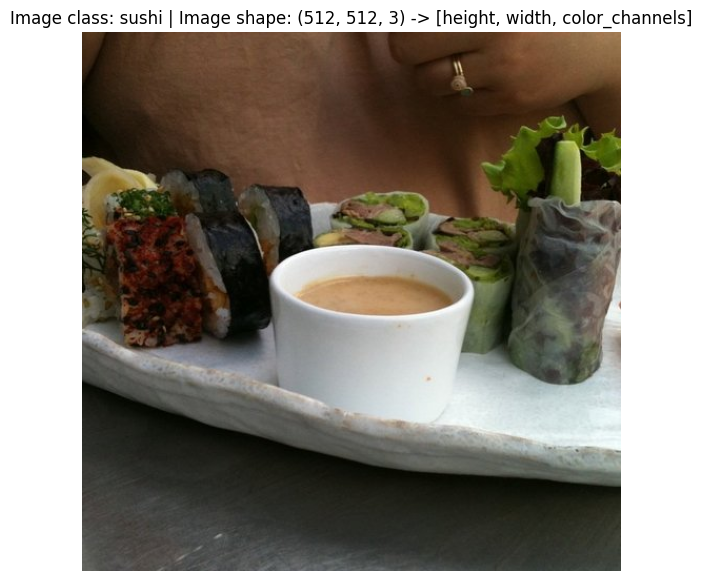

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

img_as_array=np.asarray(img)

#plot the image with matplotlib

plt.figure(figsize=(10,7))
plt.imshow(img_as_array)
plt.title(f"Image class: {image_class} | Image shape: {img_as_array.shape} -> [height, width, color_channels]")
plt.axis(False)

array([[[ 78,  52,  29],
        [ 77,  51,  28],
        [ 77,  51,  26],
        ...,
        [161, 123,  84],
        [162, 124,  85],
        [163, 125,  86]],

       [[ 76,  50,  27],
        [ 76,  50,  27],
        [ 76,  50,  25],
        ...,
        [163, 125,  86],
        [163, 125,  86],
        [164, 126,  87]],

       [[ 74,  48,  25],
        [ 74,  48,  25],
        [ 76,  50,  25],
        ...,
        [161, 123,  84],
        [161, 123,  84],
        [162, 124,  85]],

       ...,

       [[ 97,  98,  93],
        [ 98,  99,  94],
        [ 98,  99,  94],
        ...,
        [ 67,  74,  67],
        [ 66,  73,  66],
        [ 63,  70,  63]],

       [[ 96,  97,  92],
        [ 97,  98,  93],
        [ 97,  98,  93],
        ...,
        [ 68,  75,  68],
        [ 68,  75,  68],
        [ 66,  73,  66]],

       [[ 99, 100,  95],
        [101, 102,  97],
        [101, 102,  97],
        ...,
        [ 70,  77,  70],
        [ 72,  79,  72],
        [ 71,  78,  71]]], shape=(512, 512, 3), dtype=uint8)
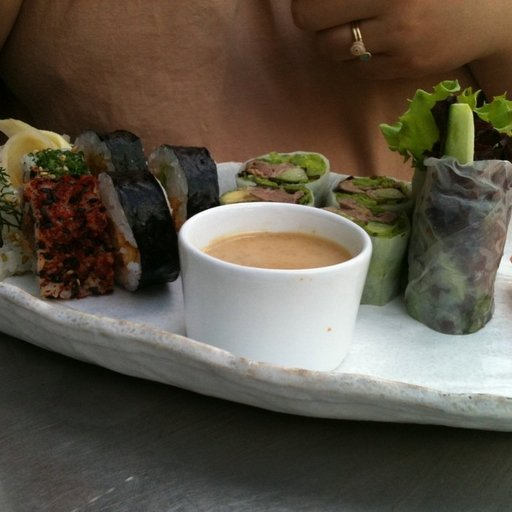

In [12]:
img_as_array

## 3.Transforming the data

Before we can use our image data with pytorch:

Turn your target data into tensors(in our case, numerical representation of our image)
Turn into a torch.utils.data.Dataset and subsequently a torch.utils.data.Dataloader, we call these Dataset and DataLoader.

In [13]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets,transforms

### 3.1Transforming the data with torchvision.transforms

In [14]:
# Write a transform for image (for Data Augmentation)
data_transform = transforms.Compose([
    #Resize our image to 64x64
    transforms.Resize(size=(64,64)),
    #Flip the image randomly on the horizontal
    transforms.RandomHorizontalFlip(p=0.5),
    #Turn the image into the torch.tensor
    transforms.ToTensor()
])

In [15]:
data_transform(img).shape

torch.Size([3, 64, 64])

In [16]:
data_transform(img).dtype

torch.float32

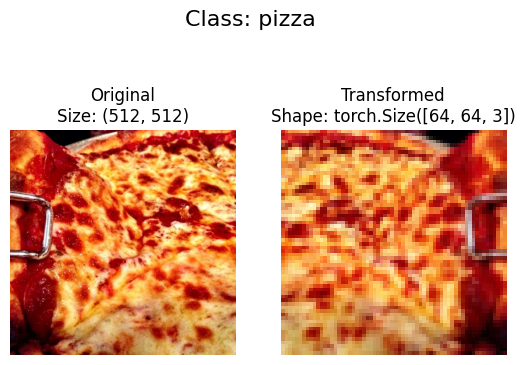

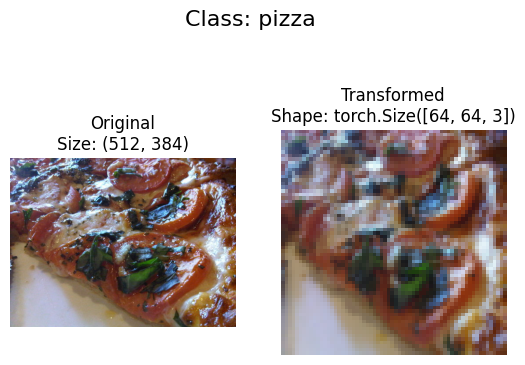

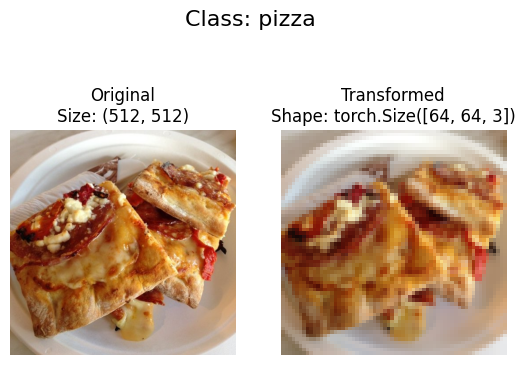

In [17]:
def plot_tranformed_images(image_paths:list,transform,n=3,seed=None):
    """ selects random images from a path of images and loads/transforms
        them then plots the original vs transformed version
    """

    if seed:
        random.seed(seed)

    random_image_paths = random.sample(image_paths,k=n)
    for image_path in random_image_paths:
        with Image.open(image_path) as f:
            fig,ax= plt.subplots(nrows=1,ncols=2)
            ax[0].imshow(f)
            ax[0].set_title(f"Original\nSize: {f.size}")
            ax[0].axis(False)

            # transform and plot target image
            transformed_image = transform(f).permute(1,2,0) #Note we will need to change shape (C,H,W)->(H,W,C)
            ax[1].imshow(transformed_image)
            ax[1].set_title(f"Transformed\nShape: {transformed_image.shape}")
            ax[1].axis("off")

            fig.suptitle(f"Class: {image_path.parent.stem}",fontsize = 16)

plot_tranformed_images(image_paths=image_path_list,
                       transform=data_transform,
                       n=3,
                       seed=None
                       )

In [18]:
image_path_list[:10]

[PosixPath('data/pizza_steak_sushi/test/pizza/195160.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/194643.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2003290.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2218680.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/1687143.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/1925494.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/416067.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2124579.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2871261.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/971934.jpg')]

In [19]:
# random.choice() selects one random element, random.sample() selects k unique elements.
random_image_path = random.sample(image_path_list,k=10)
random_image_path

[PosixPath('data/pizza_steak_sushi/train/pizza/741883.jpg'),
 PosixPath('data/pizza_steak_sushi/test/sushi/207578.jpg'),
 PosixPath('data/pizza_steak_sushi/test/sushi/2715127.jpg'),
 PosixPath('data/pizza_steak_sushi/train/sushi/2120573.jpg'),
 PosixPath('data/pizza_steak_sushi/test/sushi/1742201.jpg'),
 PosixPath('data/pizza_steak_sushi/train/steak/1849463.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/344397.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/540882.jpg'),
 PosixPath('data/pizza_steak_sushi/test/sushi/887831.jpg'),
 PosixPath('data/pizza_steak_sushi/train/pizza/2569760.jpg')]

## 4.Option 1: Loading image data using `ImageFolder`

In [20]:
# Use image folder to create the datasets
# train_dir = image_path / "train"
# test_dir = image_path / "test"
# ImageFolder 自動讀取圖片資料，並根據資料夾名稱建立分類標籤（Labels）。
from torchvision import datasets
train_data = datasets.ImageFolder(root=train_dir,
                                  transform=data_transform, # Transform for the data
                                  target_transform=None) # transform for the label / target

test_data = datasets.ImageFolder(root=test_dir,
                                 transform=data_transform,
                                 target_transform=None)

train_data,test_data

(Dataset ImageFolder
     Number of datapoints: 225
     Root location: data/pizza_steak_sushi/train
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 75
     Root location: data/pizza_steak_sushi/test
     StandardTransform
 Transform: Compose(
                Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [21]:
# Get classs names

class_names = train_data.classes #provide by imageFolder
class_names

# len(class_names)

['pizza', 'steak', 'sushi']

In [22]:
# Get classs names as dict
class_dict = train_data.class_to_idx
class_dict

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [23]:
# check the length of our dataset
len(train_data), len(test_data)

(225, 75)

In [24]:
train_data.samples[0]

('data/pizza_steak_sushi/train/pizza/1008844.jpg', 0)

In [25]:
# index on the train_data dataset to get a single image and label
img,label = train_data[0][0],train_data[0][1]
print(f"Image tensor:\n{img}")
print(f"Image shape: {img.shape}")
print(f"Image datatype: {img.dtype}")
print(f"Image label: {label}")
print(f"Label datatype: {type(label)}")

Image tensor:
tensor([[[0.1176, 0.1216, 0.1255,  ..., 0.0980, 0.1020, 0.1137],
         [0.1294, 0.1294, 0.1294,  ..., 0.0980, 0.0980, 0.1059],
         [0.1333, 0.1333, 0.1333,  ..., 0.0941, 0.0980, 0.1020],
         ...,
         [0.1686, 0.1647, 0.1686,  ..., 0.1255, 0.1098, 0.1098],
         [0.1686, 0.1647, 0.1686,  ..., 0.1098, 0.0941, 0.0902],
         [0.1647, 0.1647, 0.1686,  ..., 0.0980, 0.0863, 0.0863]],

        [[0.0588, 0.0588, 0.0588,  ..., 0.0745, 0.0706, 0.0745],
         [0.0627, 0.0627, 0.0627,  ..., 0.0745, 0.0706, 0.0745],
         [0.0706, 0.0706, 0.0706,  ..., 0.0745, 0.0745, 0.0706],
         ...,
         [0.2392, 0.2392, 0.2510,  ..., 0.1373, 0.1333, 0.1255],
         [0.2314, 0.2392, 0.2510,  ..., 0.1255, 0.1176, 0.1098],
         [0.2275, 0.2353, 0.2431,  ..., 0.1137, 0.1059, 0.1020]],

        [[0.0196, 0.0196, 0.0157,  ..., 0.0902, 0.0902, 0.0941],
         [0.0196, 0.0157, 0.0196,  ..., 0.0902, 0.0863, 0.0902],
         [0.0196, 0.0157, 0.0157,  ..., 0.09

In [26]:
label,class_names[label]

(0, 'pizza')

Original shape: torch.Size([3, 64, 64]) -> [color_channels, height, width]
Image permute shape: torch.Size([64, 64, 3]) -> [height, width, color_channels]


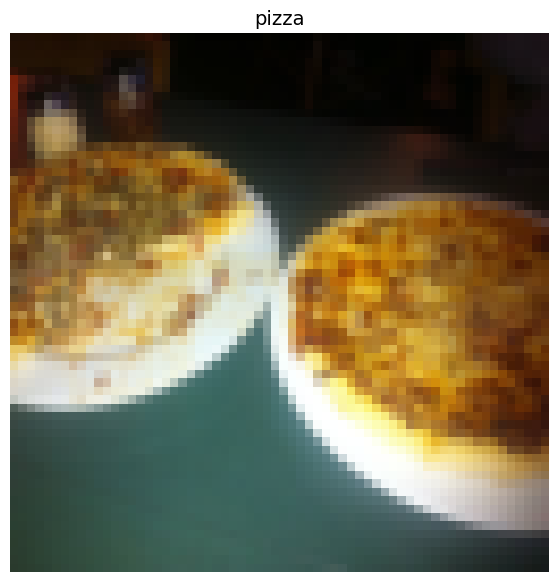

In [27]:
# Rearrange the order of dimension
img_permute = img.permute(1,2,0)

# Print out different shapes (before and after permute)
print(f"Original shape: {img.shape} -> [color_channels, height, width]")
print(f"Image permute shape: {img_permute.shape} -> [height, width, color_channels]")

# Plot the image
plt.figure(figsize=(10, 7))
# plt.imshow(img)  Incorrect: PyTorch uses [C, H, W], but Matplotlib expects [H, W, C].
plt.imshow(img_permute)
plt.axis("off")
plt.title(class_names[label], fontsize=14);

### 4.1Turn loaded images into `DataLoaders`

A `DataLoader` is going to help us turn our `Dataset's` into iterables and we can customise the `batch_size` so our model can see  `batch_size` images at a time

In [28]:
# Return the number of logical CPU cores available in the system.
import os
os.cpu_count()

2

In [29]:
# Turn train and test data into dataloaders

BATCH_SIZE = 1

# DataLoader handles batching, shuffling, and parallel data loading for efficient model training.
from torch.utils.data import DataLoader

train_dataloader = DataLoader(dataset=train_data,
                              batch_size=BATCH_SIZE,
                              num_workers=os.cpu_count(),
                              shuffle=True)#train dataset 我們會希望打散

test_dataloader = DataLoader(dataset=test_data,
                             batch_size=BATCH_SIZE,
                             num_workers=os.cpu_count(),
                             shuffle=False)

train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7c567d4e6510>,
 <torch.utils.data.dataloader.DataLoader at 0x7c567d18ccd0>)

In [30]:
len(train_dataloader)== len(train_data),len(test_dataloader)==len(test_data)

(True, True)

In [31]:
img,label = next(iter(train_dataloader))#將 DataLoader 轉成 Iterator

# Batch size will now be 1, try changing the batch_size parameter above and see what happens
print(f"Image shape: {img.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label.shape};Label: {label}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1]);Label: tensor([0])


## 5.Option 2: Loading image data with custom Dataset

1. Want to be able to load images from file
2. Want to be able to get class names from the dataset
3. Want to be able to get classes as dictionary from the dataset

**Pros:**

Can create a `Dataset` out of almost anything
Not limited to Pytorch pre-built `Dataset` functions

**Cons:**

Even though you could create a `Dataset` out of almost anything, it doesn't mean it will work.
Using a custom `Datasetoften` results in writing more code, which could be prone to errors or performance issues.

In [32]:
import os
import pathlib
import torch

from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms
from typing import Tuple,Dict,List


In [33]:
#Instance of television.datasets.ImageFolder()
train_data.classes,train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

### 5.1Creating the helper function to get class names

We Want a function to:

1. Get the class names using `os.scandir()` to traverse a target directory (ideally the dirctory is in standard image classification format).
2. Raise an error if the class names are not found (if this happens, there might be something wrong with the directory structure).
3. Turn the class names into a dict and a list and return them.

In [34]:
#Setup path for target directory
target_directory = train_dir
print(f"Train dir: {target_directory}")

##os.scandir :迭代指定目錄中的檔案與子目錄，並取得其名稱、路徑及檔案類型等資訊。
#Get the class names from the target directory
class_names_found = sorted([entry.name for entry in list(os.scandir(target_directory))])
class_names_found

Train dir: data/pizza_steak_sushi/train


['pizza', 'steak', 'sushi']

In [35]:
list(os.scandir(target_directory))

[<DirEntry 'pizza'>, <DirEntry 'steak'>, <DirEntry 'sushi'>]

In [36]:
# Make function to find classes in target directory
def find_classes(directory: str) -> Tuple[List[str], Dict[str, int]]:
    """Finds the class folder names in a target directory.

    Assumes target directory is in standard image classification format.

    Args:
        directory (str): target directory to load classnames from.

    Returns:
        Tuple[List[str], Dict[str, int]]: (list_of_class_names, dict(class_name: idx...))

    Example:
        find_classes("food_images/train")
        >>> (["class_1", "class_2"], {"class_1": 0, ...})
    """
    # 1. Get the class names by scanning the target directory
    classes = sorted(entry.name for entry in os.scandir(directory) if entry.is_dir())
    #print(f"the classes are {classes}")

    # 2. Raise an error if class names not found
    if not classes:
        raise FileNotFoundError(f"Couldn't find any classes in {directory}.")

    # 3. Create a dictionary of index labels (computers prefer numerical rather than string labels)
    class_to_idx = {cls_name: i for i, cls_name in enumerate(classes)}#dic
    return classes, class_to_idx

In [37]:
train_dir

PosixPath('data/pizza_steak_sushi/train')

In [38]:
classes,class_to_idx=find_classes(train_dir)
classes,class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

### 5.2Create a custom Dataset to replicate ImageFolder

To create our own custom dataset, we want to:

1. Subclass torch.utils.data.Dataset
2. Init our subclass with a target directory (the directory we did like to get data from) as well as a transform if we did like to transform our data.
3. Create several attributes:
- path - path of our images
- transform - the transform we'd like to use
- classes - a list of target classes
- class_to_idx = a dict of the target classes mapped to integer labels
4. Create a function to load_images this function will open the images
5. Overwrite the __len()__ method to return the length of our dataset
6. Overwrite the __getitem__   method to return a given sample when passed an index

In [39]:
# Write a custom dataset class (inherits from torch.utils.data.Dataset)
from torch.utils.data import Dataset

# 1. Subclass torch.utils.data.Dataset
class ImageFolderCustom(Dataset):

    # 2. Initialize with a targ_dir and transform (optional) parameter
    def __init__(self, targ_dir: str, transform=None) -> None:

        # 3. Create class attributes
        # Get all image paths
        self.paths = list(pathlib.Path(targ_dir).glob("*/*.jpg")) # note: you'd have to update this if you've got .png's or .jpeg's
        # Setup transforms
        self.transform = transform
        # Create classes and class_to_idx attributes
        self.classes, self.class_to_idx = find_classes(targ_dir)

    # 4. Make function to load images
    def load_image(self, index: int) -> Image.Image:
        "Opens an image via a path and returns it."
        image_path = self.paths[index]
        return Image.open(image_path)

    # 5. Overwrite the __len__() method (optional but recommended for subclasses of torch.utils.data.Dataset)
    def __len__(self) -> int:
        "Returns the total number of samples."
        return len(self.paths)

    # 6. Overwrite the __getitem__() method (required for subclasses of torch.utils.data.Dataset)
    def __getitem__(self, index: int) -> Tuple[torch.Tensor, int]:
        "Returns one sample of data, data and label (X, y)."
        img = self.load_image(index)
        class_name  = self.paths[index].parent.name # expects path in data_folder/class_name/image.jpeg
        class_idx = self.class_to_idx[class_name]

        # Transform if necessary
        if self.transform:
            return self.transform(img), class_idx # return data, label (X, y)
        else:
            return img, class_idx # return data, label (X, y)


In [40]:
class_to_idx

{'pizza': 0, 'steak': 1, 'sushi': 2}

In [41]:
#Create a transforms
from torchvision import transforms

train_transforms = transforms.Compose([
                                        transforms.Resize(size=(64,64)),
                                        transforms.RandomHorizontalFlip(p=0.5),
                                        transforms.ToTensor()
])

test_transforms = transforms.Compose([
                                        transforms.Resize(size=(64,64)),
                                        transforms.ToTensor()
])

In [42]:
train_dir,test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

In [43]:
#Test out ImageFolderCustom,train_dir and test_dir

train_data_custom = ImageFolderCustom(targ_dir=train_dir,
                                      transform=train_transforms)

test_data_custom = ImageFolderCustom(targ_dir=test_dir,
                                     transform=test_transforms)

In [44]:
train_data_custom,test_data_custom

(<__main__.ImageFolderCustom at 0x7c567d4e6a50>,
 <__main__.ImageFolderCustom at 0x7c567d18ead0>)

In [45]:
# original one
train_data

Dataset ImageFolder
    Number of datapoints: 225
    Root location: data/pizza_steak_sushi/train
    StandardTransform
Transform: Compose(
               Resize(size=(64, 64), interpolation=bilinear, max_size=None, antialias=True)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
           )

In [46]:
len(train_data),len(train_data_custom)

(225, 225)

In [47]:
len(test_data),len(test_data_custom)

(75, 75)

In [48]:
train_data_custom.class_to_idx, train_data_custom.classes

({'pizza': 0, 'steak': 1, 'sushi': 2}, ['pizza', 'steak', 'sushi'])

In [49]:
test_data_custom.class_to_idx, test_data_custom.classes

({'pizza': 0, 'steak': 1, 'sushi': 2}, ['pizza', 'steak', 'sushi'])

In [50]:
# Check for equality amongst our custom Dataset and ImageFolder Dataset
print((len(train_data_custom) == len(train_data)) & (len(test_data_custom) == len(test_data)))
print(train_data_custom.classes == train_data.classes)
print(train_data_custom.class_to_idx == train_data.class_to_idx)

True
True
True


### 5.3Create a function to display random images

1. Take in a Dataset and a number of other parameters such as classes (the names of our target classes), the number of images to display (n) and a random seed.
2. To prevent the display getting out of hand, we'll cap n at 10 images.
3. Set the random seed for reproducible plots (if seed is set).
4. Get a list of random sample indexes (we can use Python's random.sample() for this) to plot.
5. Setup a matplotlib plot.
6. Loop through the random sample indexes found in step 4 and plot them with matplotlib.
7. Make sure the sample images are of shape HWC (height, width, color channels) so we can plot them.

In [51]:
# 1.Create a function to take in a dataset

def display_random_images(dataset:torch.utils.data.Dataset,
                          classes:List[str]=None,
                          n:int=10,
                          display_shape:bool=True,
                          seed:int=None):
    #adjust the display if the n is too high
    if n>10:
      n=10
      display_shape=False
      print(f"For display purposes, n shouldn't be larger than 10, setting to 10 and removing shape display.")

    #3. setup seed
    if seed:
        random.seed(seed)#I will set 42

    #4. get random sample indexes
    random_samples_idx = random.sample(range(len(dataset)),k=n)

    # 5. Setup plot
    plt.figure(figsize=(16, 8))

    # 6. Loop through samples and display random samples
    for i, targ_sample in enumerate(random_samples_idx):
        targ_image, targ_label = dataset[targ_sample][0], dataset[targ_sample][1]

        # 7. Adjust image tensor shape for plotting: [color_channels, height, width] -> [height, width, color_channels,]
        targ_image_adjust = targ_image.permute(1, 2, 0) #c,h,w->h,w,c

        # Plot adjusted samples
        plt.subplot(1, n, i+1)
        plt.imshow(targ_image_adjust)
        plt.axis("off")
        if classes:
            title = f"class: {classes[targ_label]}"
            if display_shape:
                title = title + f"\nshape: {targ_image_adjust.shape}"
        plt.title(title)





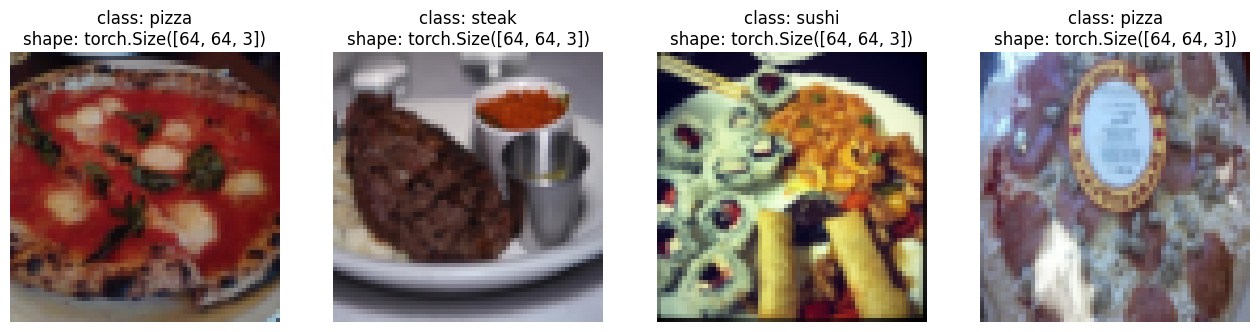

In [52]:
display_random_images(dataset=train_data_custom,
                      classes=class_names,
                      n=4,
                      seed=None)

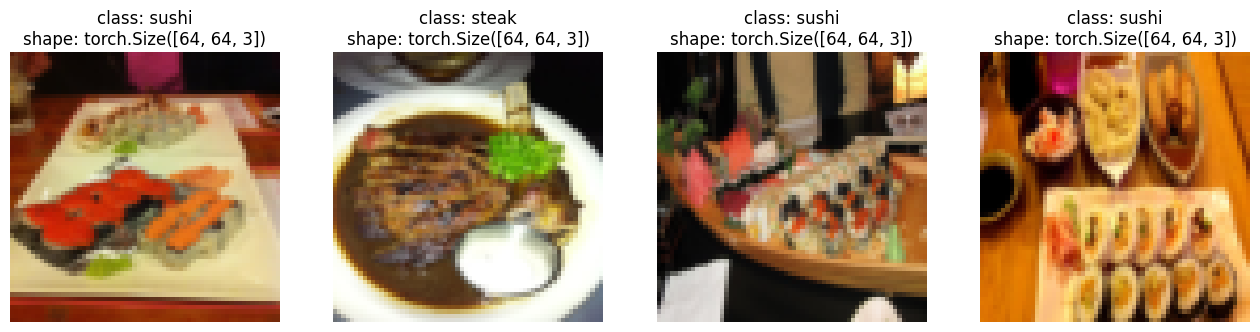

In [53]:
display_random_images(dataset=test_data_custom,
                      classes=class_names,
                      n=4,
                      seed=None)

### 5.4Turn custom loaded images into DataLoader's

In [54]:
from torch.utils.data import DataLoader

train_dataloader_custom=DataLoader(dataset=train_data_custom,
                                    batch_size=BATCH_SIZE,
                                    shuffle=True,
                                    num_workers=0)

test_dataloader_custom=DataLoader(dataset=test_data_custom,
                                  batch_size=BATCH_SIZE,
                                  shuffle=False,
                                  num_workers=0)


In [55]:
train_dataloader_custom,test_dataloader_custom

(<torch.utils.data.dataloader.DataLoader at 0x7c567c877250>,
 <torch.utils.data.dataloader.DataLoader at 0x7c567d3fcc30>)

In [56]:
# Get image and label from custom DataLoader
img_custom, label_custom = next(iter(train_dataloader_custom))

# Batch size will now be 1, try changing the batch_size parameter above and see what happens
print(f"Image shape: {img_custom.shape} -> [batch_size, color_channels, height, width]")
print(f"Label shape: {label_custom.shape}")

Image shape: torch.Size([1, 3, 64, 64]) -> [batch_size, color_channels, height, width]
Label shape: torch.Size([1])


## 6.Other forms of transforms (data augmentation)

Data augmentation is the process of altering your data in such a way that you artificially increase the diversity of your training set.



In [57]:
#Lets look trivial augument

from torchvision import transforms

train_transform = transforms.Compose([
                                      transforms.Resize(size=(224,224)),
                                      transforms.TrivialAugmentWide(num_magnitude_bins=31),#在增強方法中隨機選擇一種
                                      transforms.ToTensor()
])

test_transform = transforms.Compose([
                                    transforms.Resize(size=(224,224)),
                                    transforms.ToTensor()
])

In [58]:
# get all image path

image_path_list[:10]

[PosixPath('data/pizza_steak_sushi/test/pizza/195160.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/194643.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2003290.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2218680.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/1687143.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/1925494.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/416067.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2124579.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/2871261.jpg'),
 PosixPath('data/pizza_steak_sushi/test/pizza/971934.jpg')]

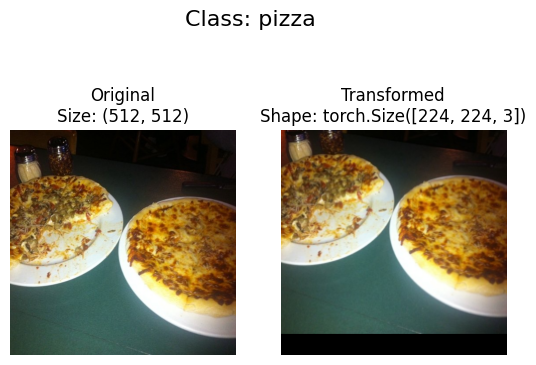

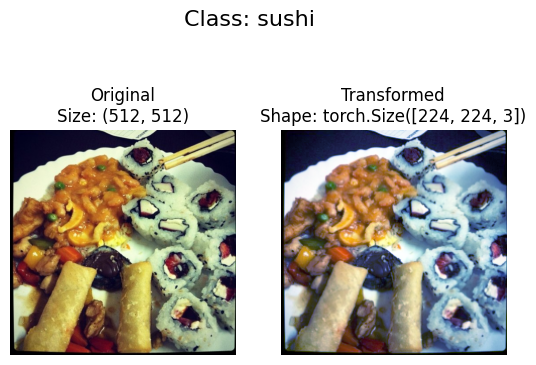

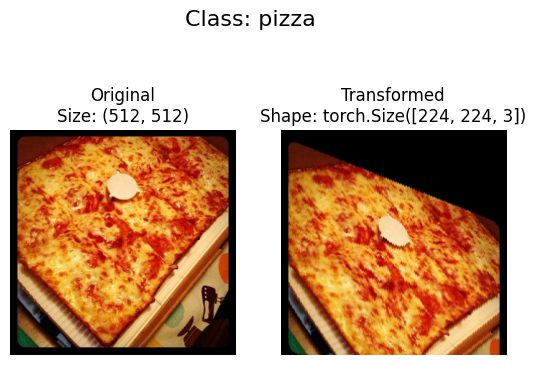

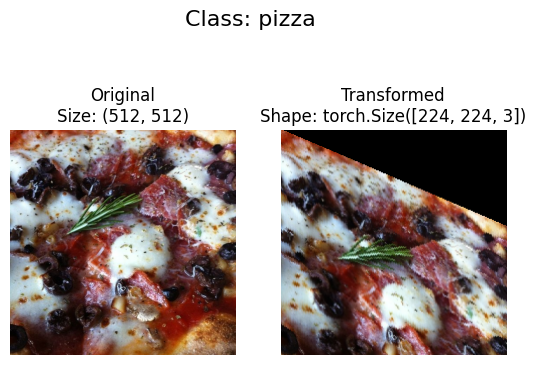

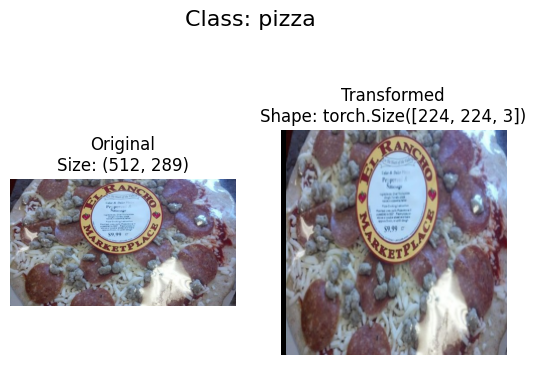

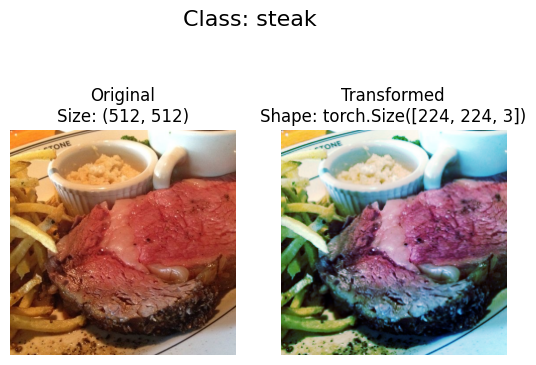

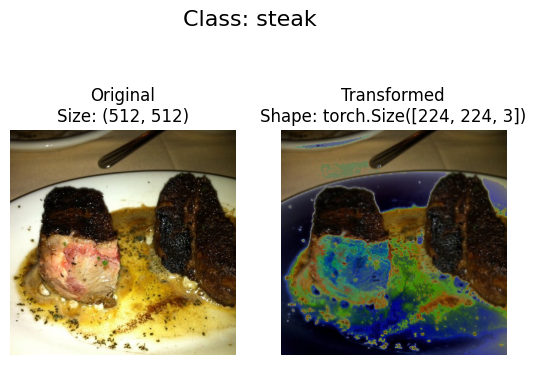

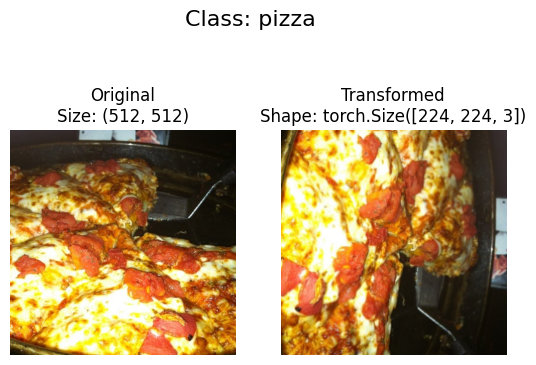

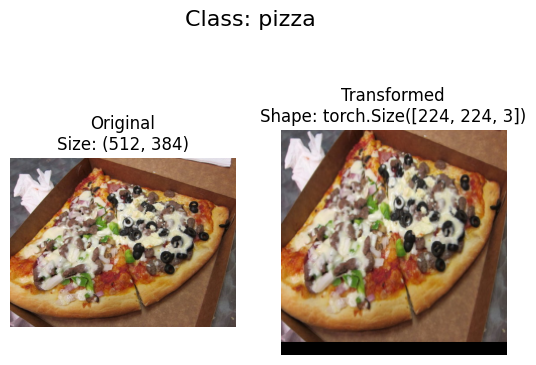

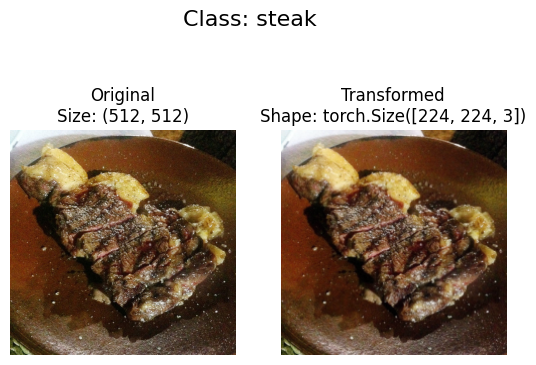

In [59]:
#Plot random image_class

plot_tranformed_images(
    image_paths=image_path_list,
    transform=train_transform,
    n=10,
    seed=None
)

## 7.Model 0: TinyVGG without Data Augmenation

## 7.1Creating transforms and loading data for Model 0

In [60]:
# Create simple transform
simple_transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

In [61]:
 #1. Load and transform data 正式的ImageFolder
from torchvision import datasets

train_data_simple = datasets.ImageFolder(
                                        root= train_dir,
                                        transform=simple_transform
)

test_data_simple = datasets.ImageFolder(
                                        root = test_dir,
                                        transform= simple_transform
)

# 2. Turn data into DataLoaders
import os
from torch.utils.data import DataLoader

# Setup batch size and number of workers
BATCH_SIZE = 32
NUM_WORKERS = 2

# Create the dataloader
train_dataloader_simple = DataLoader(
                                      dataset=train_data_simple,
                                      batch_size= BATCH_SIZE,
                                      shuffle= True,
                                      num_workers=NUM_WORKERS
)

test_dataloader_simple = DataLoader(
                                      dataset=train_data_simple,
                                      batch_size= BATCH_SIZE,
                                      shuffle= False,
                                      num_workers=NUM_WORKERS
)

train_dataloader_simple,test_dataloader_simple

(<torch.utils.data.dataloader.DataLoader at 0x7c567d483a80>,
 <torch.utils.data.dataloader.DataLoader at 0x7c567d65f410>)

### 7.2 Create TinyVGG model class

[VGG](https://medium.com/@siddheshb008/vgg-net-architecture-explained-71179310050f ) (know more about VGG)

In [62]:
class TinyVGG(nn.Module):
    """
    TinyVGG architecture
    """

    def __init__(self,
                 input_shape:int,
                 hidden_units:int,
                 output_shape:int):
        super().__init__()

        self.conv_block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),

            nn.MaxPool2d(kernel_size=2,
                         stride=2)
        )

        self.conv_block_2 = nn.Sequential(
            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),

            nn.Conv2d(in_channels=hidden_units,
                      out_channels=hidden_units,
                      kernel_size=3,
                      stride=1,
                      padding=1),
            nn.ReLU(),

        nn.MaxPool2d(kernel_size=2,
                         stride=2)

        )

        with torch.no_grad():
            dummy = torch.randn(1, input_shape, 64, 64)
            x = self.conv_block_1(dummy)
            x = self.conv_block_2(x)
            n_features = x.shape[1] * x.shape[2] * x.shape[3]

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=n_features,
                      out_features=output_shape)
        )

        self.layer_stack = nn.Sequential(
            self.conv_block_1,
            self.conv_block_2,
            self.classifier
        )


    def forward(self,x):

        return self.layer_stack(x)
        #return self.classifier(self.conv_block_2(self.conv_block_1(x)))


In [63]:
torch.manual_seed(42)

#setup model
model_T0 = TinyVGG(
                 input_shape=3,
                 hidden_units=10,
                 output_shape=len(class_names)#3
)

model_T0.to(device)

model_T0,type(class_names)

(TinyVGG(
   (conv_block_1): Sequential(
     (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (1): ReLU()
     (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (3): ReLU()
     (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
   )
   (conv_block_2): Sequential(
     (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (1): ReLU()
     (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
     (3): ReLU()
     (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
   )
   (classifier): Sequential(
     (0): Flatten(start_dim=1, end_dim=-1)
     (1): Linear(in_features=2560, out_features=3, bias=True)
   )
   (layer_stack): Sequential(
     (0): Sequential(
       (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
       (1): ReLU()
       (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
       (3): 

In [64]:
next(model_T0.parameters()).device

device(type='cuda', index=0)

### 7.3Try a forward pass on single image (to test the model)

In [65]:
# 1. Get a batch of images and labels from the DataLoader
img_batch, label_batch = next(iter(train_dataloader_simple))

# 2. Get a single image from the batch and unsqueeze the image so its shape fits the model
img_single, label_single = img_batch[0].unsqueeze(dim=0), label_batch[0]
print(f"Single image shape: {img_single.shape}\n")
print(f"Single image device: {img_single.device}\n")

#3. Perform a forward pass on a single image


model_T0.eval()
with torch.no_grad():
    #forward
    pred=model_T0(img_single.to(device))

# 4. Print out what's happening and convert model logits -> pred probs -> pred label
print(f"Output logits:\n{pred}\n")
print(f"Output prediction probabilities:\n{torch.softmax(pred, dim=1)}\n")
print(f"Output prediction label:\n{torch.argmax(torch.softmax(pred, dim=1), dim=1)}\n")
print(f"Actual label:\n{label_single}")



Single image shape: torch.Size([1, 3, 64, 64])

Single image device: cpu

Output logits:
tensor([[ 0.0324, -0.0389,  0.0595]], device='cuda:0')

Output prediction probabilities:
tensor([[0.3380, 0.3147, 0.3473]], device='cuda:0')

Output prediction label:
tensor([2], device='cuda:0')

Actual label:
1


### 7.4use `torchinfo` to get an idea of the shapes going through our model

In [66]:
# Install torchinfo if it's not available, import it if it is
try:
    import torchinfo
except:
    !pip install torchinfo
    import torchinfo

from torchinfo import summary
summary(model_T0, input_size=[1, 3, 64, 64]) # do a test pass through of an example input size

Layer (type:depth-idx)                   Output Shape              Param #
TinyVGG                                  [1, 3]                    --
├─Sequential: 1-1                        [1, 3]                    --
│    └─Sequential: 2-1                   [1, 10, 32, 32]           --
│    │    └─Conv2d: 3-1                  [1, 10, 64, 64]           280
│    │    └─ReLU: 3-2                    [1, 10, 64, 64]           --
│    │    └─Conv2d: 3-3                  [1, 10, 64, 64]           910
│    │    └─ReLU: 3-4                    [1, 10, 64, 64]           --
│    │    └─MaxPool2d: 3-5               [1, 10, 32, 32]           --
│    └─Sequential: 2-2                   [1, 10, 16, 16]           --
│    │    └─Conv2d: 3-6                  [1, 10, 32, 32]           910
│    │    └─ReLU: 3-7                    [1, 10, 32, 32]           --
│    │    └─Conv2d: 3-8                  [1, 10, 32, 32]           910
│    │    └─ReLU: 3-9                    [1, 10, 32, 32]           --
│    │    └

### 7.5 create the train and test loop function

In [67]:
import os
import requests

file_path = "helper_functions.py"

if not os.path.exists(file_path):
    url = "https://raw.githubusercontent.com/yokeswarans/pytorch-mastery-zero-to-hero/main/helper_functions.py"

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    with open(file_path, "wb") as f:
        f.write(response.content)

    print("File downloaded successfully!")
else:
    print("File already exists!")

File downloaded successfully!


In [68]:
from  helper_functions import accuracy_fn

In [69]:
def train_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module,
               optimizer: torch.optim.Optimizer,
               device: torch.device =device):
    train_loss , train_acc = 0,0
    model.to(device)
    model.train()#default

    for batch ,(X,y) in enumerate(dataloader):
        X, y = X.to(device),y.to(device)

        #forward pass
        y_pred = model(X)

        #calculate the
        loss = loss_fn(y_pred,y)
        train_loss += loss.item()

        #optimizer zero
        optimizer.zero_grad()

        #backpropagation
        loss.backward()

        #optimize step
        optimizer.step()

        y_pred_class = torch.argmax(torch.softmax(y_pred,dim =1),dim=1)

        train_acc += (y_pred_class==y).sum().item()/len(y_pred)

    # loss and accuracy per batch
    train_loss = train_loss/len(dataloader)
    train_acc = train_acc/len(dataloader)

    return train_loss,train_acc

In [71]:
# Create a test step

def test_step(model: torch.nn.Module,
               dataloader: torch.utils.data.DataLoader,
               loss_fn : torch.nn.Module,
               device: torch.device =device):

    model.eval()

    test_loss, test_acc = 0,0

    with torch.inference_mode():#or no_grad
        for batch, (X,y) in enumerate(dataloader):
            X, y = X.to(device),y.to(device)
            test_pred_logits = model(X)

            loss = loss_fn(test_pred_logits,y)
            test_loss += loss.item()# Convert a single-element tensor to a Python scalar (int or float)

            test_pred_labels = test_pred_logits.argmax(dim=1)

            test_acc += ((test_pred_labels == y).sum().item()/len(test_pred_labels))

    # Adjust metrics to get average loss and accuracy per batch
    test_loss = test_loss / len(dataloader)
    test_acc = test_acc / len(dataloader)
    return test_loss, test_acc

### 7.6Creating a `train()` function to combine `train_step()` and `test_step()`


In [72]:
from tqdm.auto import tqdm

In [73]:
# Take in various parameters required for training and test steps
def train(model: torch.nn.Module,
          train_dataloader: torch.utils.data.DataLoader,
          test_dataloader: torch.utils.data.DataLoader,
          optimizer: torch.optim.Optimizer,
          loss_fn: torch.nn.Module = nn.CrossEntropyLoss(),
          epochs: int = 5):

    results = {
               "train_loss":[],
               "train_acc":[],
               "test_loss":[],
               "test_acc":[]
               }

    for epoch in tqdm(range(epochs)):

        print(f"\nEpoch {epoch+1}")
        print(f"Model on: {next(model.parameters()).device}")

        train_loss,train_acc = train_step(model=model,
                   dataloader=train_dataloader,
                   loss_fn=loss_fn,
                   optimizer=optimizer)

        test_loss,test_acc =test_step(model=model,
                                      dataloader=test_dataloader,
                                      loss_fn=loss_fn)

        # 4. Print out what's happening
        print(
            f"Epoch: {epoch+1} | "
            f"train_loss: {train_loss:.4f} | "
            f"train_acc: {train_acc:.4f} | "
            f"test_loss: {test_loss:.4f} | "
            f"test_acc: {test_acc:.4f}"
        )

        # 5. Update results dictionary
        # Ensure all data is moved to CPU and converted to float for storage
        results["train_loss"].append(train_loss.item() if isinstance(train_loss, torch.Tensor) else train_loss)
        results["train_acc"].append(train_acc.item() if isinstance(train_acc, torch.Tensor) else train_acc)
        results["test_loss"].append(test_loss.item() if isinstance(test_loss, torch.Tensor) else test_loss)
        results["test_acc"].append(test_acc.item() if isinstance(test_acc, torch.Tensor) else test_acc)

    # 6. Return the filled results at the end of the epochs
    return results

### 7.7 Train and Evalute model_T0

In [77]:
#Instance of television.datasets.ImageFolder()
train_data.classes,train_data.class_to_idx

(['pizza', 'steak', 'sushi'], {'pizza': 0, 'steak': 1, 'sushi': 2})

In [79]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

NUM_EPOCHS = 5

model_T0 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)

#next(model_0.parameters()).device

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_T0.parameters(),
                             lr=0.01)

# Start the timer
from timeit import default_timer as timer
start_time = timer()

# Train model_0 we package together just now
model_T0_results = train(model=model_T0,
                        train_dataloader=train_dataloader_simple,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS)

# End the timer and print out how long it took
end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1
Model on: cuda:0
Epoch: 1 | train_loss: 1.1541 | train_acc: 0.2539 | test_loss: 1.0975 | test_acc: 0.3047

Epoch 2
Model on: cuda:0
Epoch: 2 | train_loss: 1.0988 | train_acc: 0.2969 | test_loss: 1.1009 | test_acc: 0.2930

Epoch 3
Model on: cuda:0
Epoch: 3 | train_loss: 1.0964 | train_acc: 0.2930 | test_loss: 1.1038 | test_acc: 0.3047

Epoch 4
Model on: cuda:0
Epoch: 4 | train_loss: 1.1054 | train_acc: 0.3047 | test_loss: 1.1052 | test_acc: 0.3047

Epoch 5
Model on: cuda:0
Epoch: 5 | train_loss: 1.1038 | train_acc: 0.3047 | test_loss: 1.1032 | test_acc: 0.3047
Total training time: 7.805 seconds


In [80]:
model_T0_results

{'train_loss': [1.1540761888027191,
  1.0987642407417297,
  1.0964117795228958,
  1.105441927909851,
  1.103812724351883],
 'train_acc': [0.25390625, 0.296875, 0.29296875, 0.3046875, 0.3046875],
 'test_loss': [1.0975142419338226,
  1.1009299159049988,
  1.1037617027759552,
  1.1052334904670715,
  1.1031801849603653],
 'test_acc': [0.3046875, 0.29296875, 0.3046875, 0.3046875, 0.3046875]}

### 7.8 Plot the loss curve of model_T0


In [85]:
# Get the model_0_result keys

model_T0_results.keys()

dict_keys(['train_loss', 'train_acc', 'test_loss', 'test_acc'])

In [86]:
def plot_loss_curves(results: Dict[str, List[float]]):
    """Plots training curves of a results dictionary.

    Args:
        results (dict): dictionary containing list of values, e.g.
            {"train_loss": [...],
             "train_acc": [...],
             "test_loss": [...],
             "test_acc": [...]}
    """

    # Get the loss values of the results dictionary (training and test)
    loss = results['train_loss']
    test_loss = results['test_loss']

    # Get the accuracy values of the results dictionary (training and test)
    accuracy = results['train_acc']
    test_accuracy = results['test_acc']

    # Figure out how many epochs there were
    epochs = range(len(results['train_loss']))

    # Setup a plot
    plt.figure(figsize=(15, 7))

    # Plot loss
    plt.subplot(1, 2, 1)
    plt.plot(epochs, loss, label='train_loss')
    plt.plot(epochs, test_loss, label='test_loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.legend()

    # Plot accuracy
    plt.subplot(1, 2, 2)
    plt.plot(epochs, accuracy, label='train_accuracy')
    plt.plot(epochs, test_accuracy, label='test_accuracy')
    plt.title('Accuracy')
    plt.xlabel('Epochs')
    plt.legend();

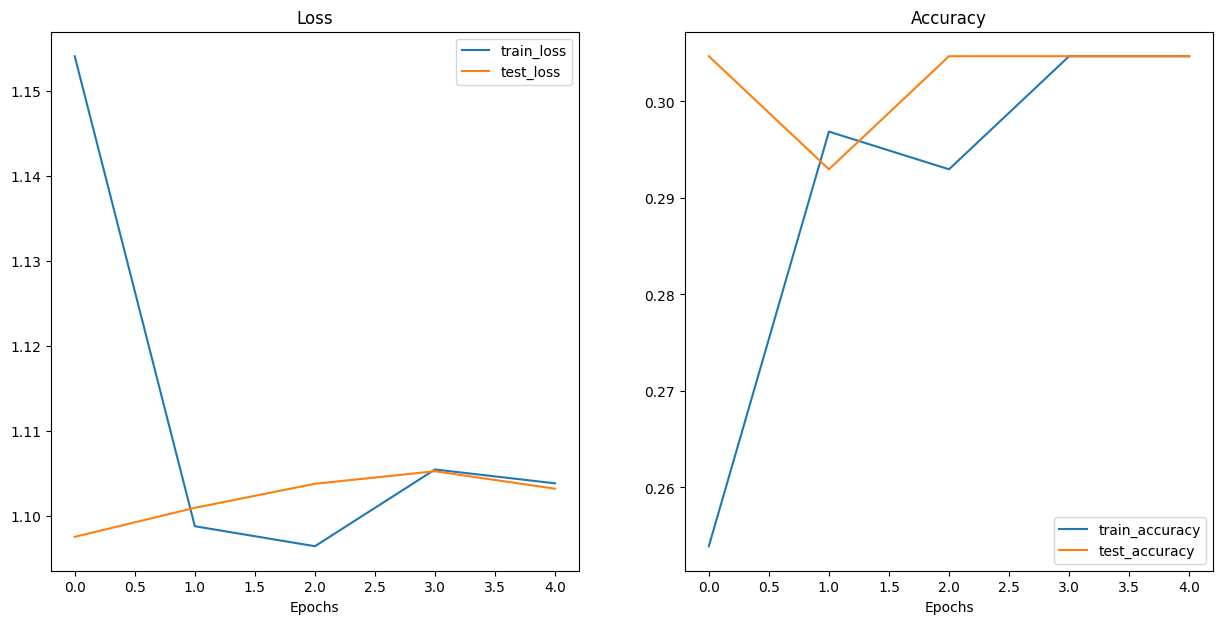

In [87]:
plot_loss_curves(model_T0_results)

###Tiny VGG with Data Augmenation

In [91]:
# create training transform with TrivialAugment

train_transform_trivial_augment = transforms.Compose([
    transforms.Resize((64,64)),
    transforms.TrivialAugmentWide(num_magnitude_bins=31),
    transforms.ToTensor()
])

#Create a testing transforms

test_transform = transforms.Compose([
    transforms.Resize((64,64)),
    transforms.ToTensor()
])

###Create train and test Dataset's and DataLoader's

In [88]:
train_dir

PosixPath('data/pizza_steak_sushi/train')

In [92]:
train_data_augment = datasets.ImageFolder(root=train_dir,
                                          transform=train_transform_trivial_augment)

test_data_simple = datasets.ImageFolder(root=test_dir,
                                        transform=test_transform)

In [102]:
# Turn the dataset into the data loaders

import os
BATCH_SIZE = 32
NUM_WORKERS = os.cpu_count()

torch.manual_seed(42)
train_dataloader_augmented = DataLoader(dataset=train_data_augment,
                                        batch_size=BATCH_SIZE,
                                        shuffle=True,
                                        num_workers=NUM_WORKERS)
test_dataloader_simple = DataLoader(dataset=test_data_simple,
                                    batch_size=BATCH_SIZE,
                                    num_workers=NUM_WORKERS)


In [103]:
train_dataloader_augmented,test_dataloader_simple

(<torch.utils.data.dataloader.DataLoader at 0x7c567d50b350>,
 <torch.utils.data.dataloader.DataLoader at 0x7c567d50bc50>)


### Construct and train Model T1

In [96]:
model_T1 = TinyVGG(input_shape=3,
                  hidden_units=10,
                  output_shape=len(train_data.classes)).to(device)

In [97]:
next(model_T1.parameters()).device

device(type='cuda', index=0)

In [105]:
len(train_data_augment),len(test_data_simple)

(225, 75)

In [106]:
model_T1

TinyVGG(
  (conv_block_1): Sequential(
    (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (conv_block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2560, out_features=3, bias=True)
  )
  (layer_stack): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU()
      (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (3): ReLU()
      (4): MaxPool

In [109]:
# Train mode  train() is the function we package together before

torch.manual_seed(42)
torch.cuda.manual_seed(42)

NUM_EPOCHS = 5

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=model_T1.parameters(),
                             lr = 0.01)


from timeit import default_timer as Timer
start_time = timer()

model_T1_results = train(model=model_T1,
                        train_dataloader=train_dataloader_augmented,
                        test_dataloader=test_dataloader_simple,
                        optimizer=optimizer,
                        loss_fn=loss_fn,
                        epochs=NUM_EPOCHS)


end_time = timer()
print(f"Total training time: {end_time-start_time:.3f} seconds")

  0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1
Model on: cuda:0
Epoch: 1 | train_loss: 1.3347 | train_acc: 0.3867 | test_loss: 1.6127 | test_acc: 0.2604

Epoch 2
Model on: cuda:0
Epoch: 2 | train_loss: 1.1506 | train_acc: 0.4219 | test_loss: 1.1047 | test_acc: 0.2604

Epoch 3
Model on: cuda:0
Epoch: 3 | train_loss: 1.0927 | train_acc: 0.4258 | test_loss: 1.1105 | test_acc: 0.2604

Epoch 4
Model on: cuda:0
Epoch: 4 | train_loss: 1.1015 | train_acc: 0.3047 | test_loss: 1.1138 | test_acc: 0.2604

Epoch 5
Model on: cuda:0
Epoch: 5 | train_loss: 1.0899 | train_acc: 0.4258 | test_loss: 1.1193 | test_acc: 0.2604
Total training time: 6.483 seconds


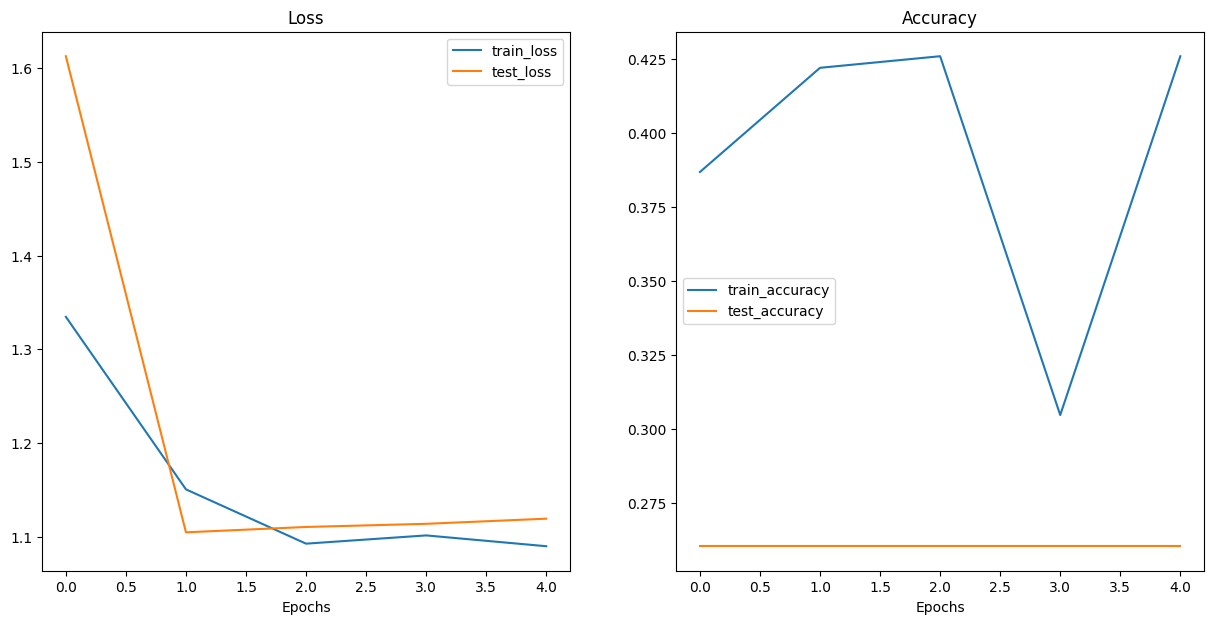

In [110]:
#Plot the loss curves of Model
plot_loss_curves(model_T1_results)

### Compare model results

In [111]:
import pandas as pd
model_0_df = pd.DataFrame(model_T0_results)
model_1_df = pd.DataFrame(model_T1_results)

model_0_df, model_1_df

(   train_loss  train_acc  test_loss  test_acc
 0    1.154076   0.253906   1.097514  0.304688
 1    1.098764   0.296875   1.100930  0.292969
 2    1.096412   0.292969   1.103762  0.304688
 3    1.105442   0.304688   1.105233  0.304688
 4    1.103813   0.304688   1.103180  0.304688,
    train_loss  train_acc  test_loss  test_acc
 0    1.334664   0.386719   1.612699  0.260417
 1    1.150570   0.421875   1.104747  0.260417
 2    1.092651   0.425781   1.110467  0.260417
 3    1.101455   0.304688   1.113830  0.260417
 4    1.089921   0.425781   1.119298  0.260417)

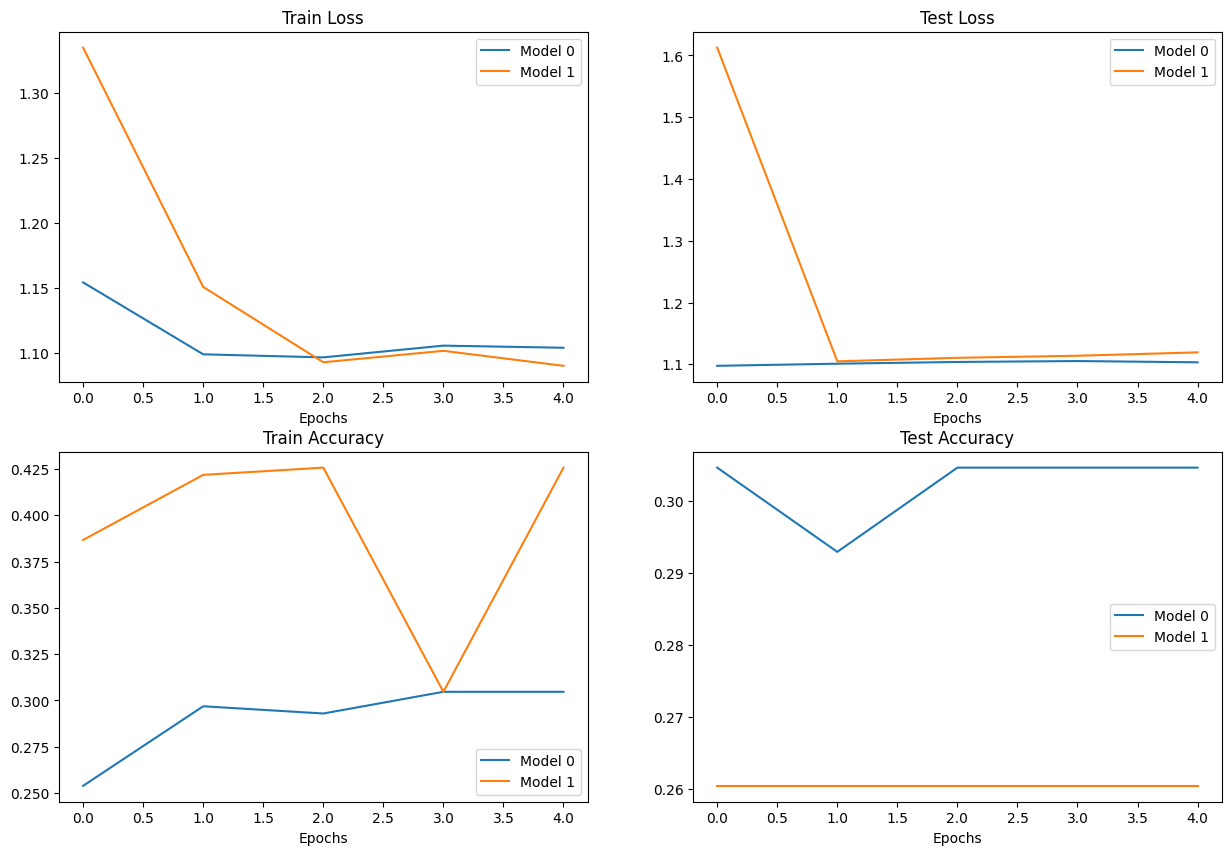

In [112]:
# Setup a plot
plt.figure(figsize=(15, 10))

# Get number of epochs
epochs = range(len(model_0_df))

# Plot train loss
plt.subplot(2, 2, 1)
plt.plot(epochs, model_0_df["train_loss"], label="Model 0")
plt.plot(epochs, model_1_df["train_loss"], label="Model 1")
plt.title("Train Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot test loss
plt.subplot(2, 2, 2)
plt.plot(epochs, model_0_df["test_loss"], label="Model 0")
plt.plot(epochs, model_1_df["test_loss"], label="Model 1")
plt.title("Test Loss")
plt.xlabel("Epochs")
plt.legend()

# Plot train accuracy
plt.subplot(2, 2, 3)
plt.plot(epochs, model_0_df["train_acc"], label="Model 0")
plt.plot(epochs, model_1_df["train_acc"], label="Model 1")
plt.title("Train Accuracy")
plt.xlabel("Epochs")
plt.legend()

# Plot test accuracy
plt.subplot(2, 2, 4)
plt.plot(epochs, model_0_df["test_acc"], label="Model 0")
plt.plot(epochs, model_1_df["test_acc"], label="Model 1")
plt.title("Test Accuracy")
plt.xlabel("Epochs")
plt.legend();

In [114]:
data_path

PosixPath('data')

In [113]:
import requests

custom_image_path = data_path / "test_image.jpeg"
if not custom_image_path.is_file():
    with open(custom_image_path, "wb") as f:
        # When downloading from GitHub, need to use the "raw" file link
        request = requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/04-pizza-dad.jpeg")
        print(f"Downloading {custom_image_path}...")
        f.write(request.content)
else:
    print(f"{custom_image_path} already exists, skipping download.")

### loading custom image with pytorch

We have to make sure our custom image is in same format as the data our model was trained on.

- In tensor form with datatype
- of shape 64x64x3
- On the right device

In [115]:
import torchvision

#Read in custom image_class
custom_image_uint8 = torchvision.io.read_image(str(custom_image_path))

custom_image_uint8

tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], dtype=torch.uint8)

In [125]:
device="cuda" if torch.cuda.is_available() else "cpu"

device


'cuda'

In [126]:
custom_image_uint8.to(device)

tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], device='cuda:0',
       dtype=torch.uint8)

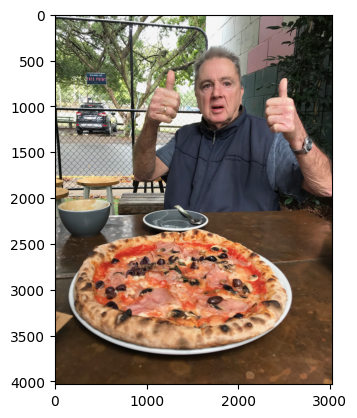

In [128]:
plt.imshow(custom_image_uint8.permute(1,2,0))


In [129]:
# Print out image data
print(f"Custom image tensor:\n{custom_image_uint8}\n")
print(f"Custom image shape: {custom_image_uint8.shape}\n")
print(f"Custom image dtype: {custom_image_uint8.dtype}")

Custom image tensor:
tensor([[[154, 173, 181,  ...,  21,  18,  14],
         [146, 165, 181,  ...,  21,  18,  15],
         [124, 146, 172,  ...,  18,  17,  15],
         ...,
         [ 72,  59,  45,  ..., 152, 150, 148],
         [ 64,  55,  41,  ..., 150, 147, 144],
         [ 64,  60,  46,  ..., 149, 146, 143]],

        [[171, 190, 193,  ...,  22,  19,  15],
         [163, 182, 193,  ...,  22,  19,  16],
         [141, 163, 184,  ...,  19,  18,  16],
         ...,
         [ 55,  42,  28,  ..., 107, 104, 103],
         [ 47,  38,  24,  ..., 108, 104, 102],
         [ 47,  43,  29,  ..., 107, 104, 101]],

        [[119, 138, 147,  ...,  17,  14,  10],
         [111, 130, 145,  ...,  17,  14,  11],
         [ 87, 111, 136,  ...,  14,  13,  11],
         ...,
         [ 35,  22,   8,  ...,  52,  52,  48],
         [ 27,  18,   4,  ...,  50,  49,  44],
         [ 27,  23,   9,  ...,  49,  46,  43]]], dtype=torch.uint8)

Custom image shape: torch.Size([3, 4032, 3024])

Custom image dty

In [130]:
model_T1.eval()
with torch.inference_mode():
    model_T1(custom_image_uint8)

RuntimeError: Input type (unsigned char) and bias type (float) should be the same

In [133]:
custom_image = torchvision.io.read_image(str(custom_image_path)).type(torch.float32) / 255
custom_image,custom_image.dtype,custom_image.shape

(tensor([[[0.6039, 0.6784, 0.7098,  ..., 0.0824, 0.0706, 0.0549],
          [0.5725, 0.6471, 0.7098,  ..., 0.0824, 0.0706, 0.0588],
          [0.4863, 0.5725, 0.6745,  ..., 0.0706, 0.0667, 0.0588],
          ...,
          [0.2824, 0.2314, 0.1765,  ..., 0.5961, 0.5882, 0.5804],
          [0.2510, 0.2157, 0.1608,  ..., 0.5882, 0.5765, 0.5647],
          [0.2510, 0.2353, 0.1804,  ..., 0.5843, 0.5725, 0.5608]],
 
         [[0.6706, 0.7451, 0.7569,  ..., 0.0863, 0.0745, 0.0588],
          [0.6392, 0.7137, 0.7569,  ..., 0.0863, 0.0745, 0.0627],
          [0.5529, 0.6392, 0.7216,  ..., 0.0745, 0.0706, 0.0627],
          ...,
          [0.2157, 0.1647, 0.1098,  ..., 0.4196, 0.4078, 0.4039],
          [0.1843, 0.1490, 0.0941,  ..., 0.4235, 0.4078, 0.4000],
          [0.1843, 0.1686, 0.1137,  ..., 0.4196, 0.4078, 0.3961]],
 
         [[0.4667, 0.5412, 0.5765,  ..., 0.0667, 0.0549, 0.0392],
          [0.4353, 0.5098, 0.5686,  ..., 0.0667, 0.0549, 0.0431],
          [0.3412, 0.4353, 0.5333,  ...,

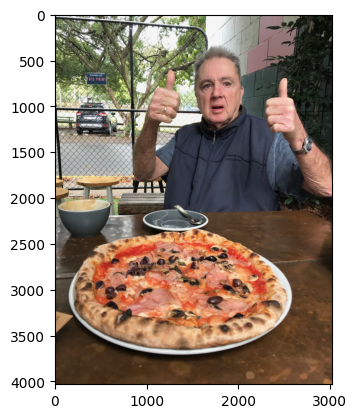

In [134]:
plt.imshow(custom_image.permute(1,2,0))

In [144]:
# lets transform the image_class

custom_image_transform = transforms.Compose([
    transforms.Resize((64,64)),
])

In [145]:
custom_image_transformed = custom_image_transform(custom_image)
# Print out original shape and new shape
print(f"Original shape: {custom_image.shape}")
print(f"New shape: {custom_image_transformed.shape}")

Original shape: torch.Size([3, 4032, 3024])
New shape: torch.Size([3, 64, 64])


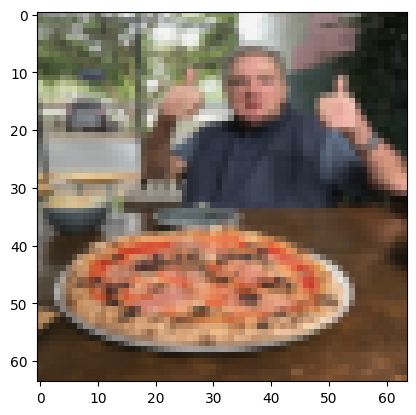

In [146]:
plt.imshow(custom_image_transformed.permute(1,2,0
))

In [147]:
custom_image_transformed_unsqueeze = (custom_image_transformed).unsqueeze(dim=0)
custom_image_transformed_unsqueeze.shape

torch.Size([1, 3, 64, 64])

In [149]:
# This will error : no batch size
model_T1.eval()
with torch.inference_mode():#no_grad()

    #calcualte the logits
    custom_image_pred = model_T1(custom_image_transformed_unsqueeze.to(device))

In [150]:
custom_image_pred

tensor([[ 0.0749, -0.0086, -0.0711]], device='cuda:0')

In [156]:
custom_image_pred_probs = torch.softmax(custom_image_pred,dim=1)
custom_image_pred_probs,torch.argmax(custom_image_pred_probs)

(tensor([[0.3592, 0.3304, 0.3104]], device='cuda:0'),
 tensor(0, device='cuda:0'))

In [157]:
train_data.classes #so the idx=0 is correct answer(the dad with pizza)

['pizza', 'steak', 'sushi']

In [158]:
index = torch.argmax(custom_image_pred_probs)
index

tensor(0, device='cuda:0')

In [160]:
class_names

['pizza', 'steak', 'sushi']

In [161]:
prediction = class_names[index]
prediction

'pizza'

### Putting custom image prediction together: building a function

Doing all of the above steps every time you'd like to make a prediction on a custom image would quickly become tedious.

So let's put them all together in a function we can easily use over and over again.

Specifically, let's make a function that:

1. Takes in a target image path and converts to the right
2. datatype for our model (torch.float32).
3. Makes sure the target image pixel values are in the range [0, 1].
4. Transforms the target image if necessary.
5. Makes sure the model is on the target device.
6. Makes a prediction on the target image with a trained model (ensuring the image is the right size and on the same device as the model).
7. Converts the model's output logits to prediction probabilities.
8. Converts the prediction probabilities to prediction labels.
Plots the target image alongside the model prediction and prediction probability.

In [162]:
def pred_and_plot_image(model: torch.nn.Module,
                        image_path: str,
                        class_names: List[str] = None,
                        transform=None,
                        device: torch.device = device):
    """Makes a prediction on a target image and plots the image with its prediction."""

    # 1. Load in image and convert the tensor values to float32
    target_image = torchvision.io.read_image(str(image_path)).type(torch.float32)

    # 2. Divide the image pixel values by 255 to get them between [0, 1]
    target_image = target_image / 255.

    # 3. Transform if necessary
    if transform:
        target_image = transform(target_image)

    # 4. Make sure the model is on the target device
    model.to(device)

    # 5. Turn on model evaluation mode and inference mode
    model.eval()
    with torch.inference_mode():
        # Add an extra dimension to the image
        target_image = target_image.unsqueeze(dim=0)

        # Make a prediction on image with an extra dimension and send it to the target device
        target_image_pred = model(target_image.to(device))

    # 6. Convert logits -> prediction probabilities (using torch.softmax() for multi-class classification)
    target_image_pred_probs = torch.softmax(target_image_pred, dim=1)

    # 7. Convert prediction probabilities -> prediction labels
    target_image_pred_label = torch.argmax(target_image_pred_probs, dim=1)

    # 8. Plot the image alongside the prediction and prediction probability
    plt.imshow(target_image.squeeze().permute(1, 2, 0)) # make sure it's the right size for matplotlib
    if class_names:
        title = f"Pred: {class_names[target_image_pred_label.cpu()]} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    else:
        title = f"Pred: {target_image_pred_label} | Prob: {target_image_pred_probs.max().cpu():.3f}"
    plt.title(title)
    plt.axis(False);

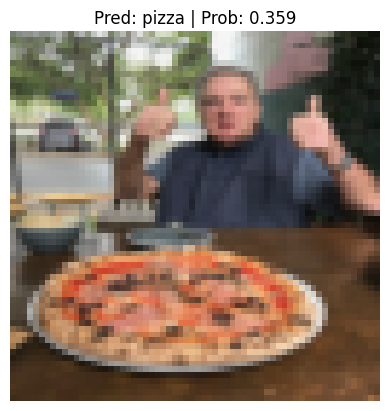

In [163]:
# Pred on our custom image
pred_and_plot_image(model=model_T1,
                    image_path=custom_image_path,
                    class_names=class_names,
                    transform=custom_image_transform,
                    device=device)
